##Pre and libs

In [ ]:
%pip uninstall -y numpy scipy qiskit qiskit-terra qiskit-aer qiskit-ibmq-provider qiskit-ibm-runtime qiskit-algorithms qiskit-machine-learning qiskit-optimization qiskit-nature qiskit-experiments qiskit-finance qiskit-quantum-info qiskit-utils


Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2
Found existing installation: scipy 1.16.3
Uninstalling scipy-1.16.3:
  Successfully uninstalled scipy-1.16.3


In [ ]:
pip list | grep qiskit


In [ ]:

%pip install "numpy==2.0.2" "scipy>=1.14.0"


  Using cached numpy-2.0.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (60 kB)
  Using cached scipy-1.16.3-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (62 kB)
Using cached numpy-2.0.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (19.2 MB)
Using cached scipy-1.16.3-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (35.7 MB)


In [ ]:
%pip install "qiskit==1.2.4" "qiskit-aer==0.15.1" "qiskit-algorithms==0.3.1"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.5/310.5 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 84.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 21.8 MB/s eta 0:00:00


#Code

/tmp/ipython-input-3660194443.py:18: DeprecationWarning: The class ``qiskit.primitives.sampler.Sampler`` is deprecated as of qiskit 1.2. It will be removed no earlier than 3 months after the release date. All implementations of the `BaseSamplerV1` interface have been deprecated in favor of their V2 counterparts. The V2 alternative for the `Sampler` class is `StatevectorSampler`.
  sampler = Sampler()


Sample Space Example
Sample space (first 20 possible samples):
[  50.  100.  150.  200.  250.  300.  350.  400.  450.  500.  550.  600.
  650.  700.  750.  800.  850.  900.  950. 1000.]

True success probability (a) = 0.2
That means ~20.0% of the time f(x)=1 (success).

Running Quantum Amplitude Estimation ...

⏱️ CLASSICAL vs QUANTUM ESTIMATION RESULTS
   Samples |   Estimation |      Error |   Time (s)
--------------------------------------------------
       100 | 0.22000000000000000111 | 0.01999999999999999001 | 0.00012190500001452165
       681 | 0.18502202643171805629 | 0.01497797356828195481 | 0.00006840000000352120
      4641 | 0.19758672699849169629 | 0.00241327300150831481 | 0.00060094900001672613
     31622 | 0.20280184681550819659 | 0.00280184681550818548 | 0.00047189800000069226
    215443 | 0.19892500568595869459 | 0.00107499431404131651 | 0.00266638099998317557
   1467799 | 0.20027469701232933352 | 0.00027469701232932242 | 0.01793712200000641133
  10000000 | 0.1998148999

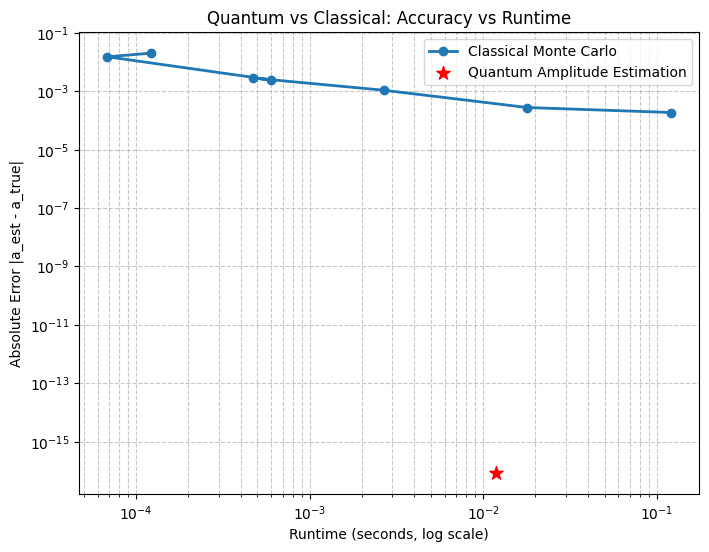

SUMMARY
True probability (a) = 0.2
Quantum estimated a  = 0.20000000000000009437
Quantum runtime      = 0.0118 s
Quantum error        = 0.00000000000000008327
Best classical (10^6 samples) estimation = 0.19981489999999998974 (error=0.00018510000000002136)
----------------------------------------------------------
Expected scaling:
   • Classical Monte Carlo: Error ~ 1/sqrt(N)
   • Quantum AE: Error ~ 1/N   (Quadratic speedup!)
----------------------------------------------------------


In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt

#from qiskit.primitives import StatevectorSampler
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit.primitives import Sampler  # Qiskit native CPU sampler
from qiskit.circuit.library import StatePreparation
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem
from qiskit_algorithms.utils import algorithm_globals

# ===============================================================
# Setup
# ===============================================================
algorithm_globals.random_seed = 42
#sampler = StatevectorSampler()
#sampler = AerSampler(run_options={"shots": 100},backend_options={"device": "CPU", "max_parallel_threads": 1})
sampler = Sampler()

# Define the "true" success probability
true_a = 0.2
theta = 2 * np.arcsin(np.sqrt(true_a))
prep = StatePreparation([np.cos(theta / 2), np.sin(theta / 2)])
prep.name = "A"

# Fix: add missing attributes
prep.state_preparation = prep
prep.num_ancillas = 0

print("==========================================================")
print("Sample Space Example")
sample_space = np.linspace(50, 1000, 20)
print("Sample space (first 20 possible samples):")
print(sample_space)
print(f"\nTrue success probability (a) = {true_a}")
print(f"That means ~{true_a*100:.1f}% of the time f(x)=1 (success).")
print("==========================================================\n")

# ===============================================================
# Classical Monte Carlo Estimation
# ===============================================================
def classical_monte_carlo(true_prob, n_samples):
    samples = np.random.rand(n_samples)
    est = np.mean(samples < true_prob)
    return est

sample_sizes = np.logspace(2, 7, num=7, dtype=int)  # 10² → 10⁶
mc_times, mc_errors, mc_results = [], [], []

for n in sample_sizes:
    t0 = time.perf_counter()
    est = classical_monte_carlo(true_a, n)
    t1 = time.perf_counter()
    mc_times.append(t1 - t0)
    mc_errors.append(abs(est - true_a))
    mc_results.append(est)

# ===============================================================
# Quantum Amplitude Estimation (QAE)
# ===============================================================
print("Running Quantum Amplitude Estimation ...")

# Define estimation problem properly
problem = EstimationProblem(
    state_preparation=prep,
    objective_qubits=[0]  # qubit measuring success
)

# Use Iterative Amplitude Estimation
qae = IterativeAmplitudeEstimation(
    epsilon_target=0.001,  # target precision (1%)
    alpha=0.05,           # confidence level
    sampler=sampler
)

t_start = time.perf_counter()
qae_result = qae.estimate(problem)
t_qae = time.perf_counter() - t_start

# ===============================================================
# Display Results
# ===============================================================
print("\n==========================================================")
print("⏱️ CLASSICAL vs QUANTUM ESTIMATION RESULTS")
print("==========================================================")
print(f"{'Samples':>10} | {'Estimation':>12} | {'Error':>10} | {'Time (s)':>10}")
print("-"*50)
for n, est, err, t in zip(sample_sizes, mc_results, mc_errors, mc_times):
    print(f"{n:10d} | {est:12.20f} | {err:10.20f} | {t:10.20f}")

print("----------------------------------------------------------")
print(f"Quantum (QAE)  | {qae_result.estimation_processed:12.20f} | {abs(qae_result.estimation_processed - true_a):10.20f} | {t_qae:10.20f}")
print("==========================================================\n")

# ===============================================================
# Plot Results
# ===============================================================
plt.figure(figsize=(8,6))
plt.loglog(mc_times, mc_errors, 'o-', label="Classical Monte Carlo", linewidth=2)
plt.scatter(t_qae, abs(qae_result.estimation_processed - true_a),
            color='r', s=100, marker='*', label="Quantum Amplitude Estimation")
plt.xlabel("Runtime (seconds, log scale)")
plt.ylabel("Absolute Error |a_est - a_true|")
plt.title("Quantum vs Classical: Accuracy vs Runtime")
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.legend()
plt.show()

# ===============================================================
# Print Summary
# ===============================================================
print("SUMMARY")
print(f"True probability (a) = {true_a}")
print(f"Quantum estimated a  = {qae_result.estimation_processed:.20f}")
print(f"Quantum runtime      = {t_qae:.4f} s")
print(f"Quantum error        = {abs(qae_result.estimation_processed - true_a):.20f}")
print(f"Best classical (10^6 samples) estimation = {mc_results[-1]:.20f} (error={mc_errors[-1]:.20f})")
print("----------------------------------------------------------")
print("Expected scaling:")
print("   • Classical Monte Carlo: Error ~ 1/sqrt(N)")
print("   • Quantum AE: Error ~ 1/N   (Quadratic speedup!)")
print("----------------------------------------------------------")


In [ ]:
print("\n==========================================================")
print("SUMMARY TABLE (EXACT VALUES)")
print("==========================================================")
print(f"{'Classically estimated a':<30} | {'Quantum estimated a':<30} | {'Classical error':<30} | {'Quantum error':<30} | {'Classical runtime (s)':<30} | {'Quantum runtime (s)':<30}")
print("-" * 188)
print(f"{mc_results[-1]:<30.20f} | {qae_result.estimation_processed:<30.20f} | {mc_errors[-1]:<30.20f} | {abs(qae_result.estimation_processed - true_a):<30.20f} | {mc_times[-1]:<30.20f} | {t_qae:<30.20f}")
print("==========================================================\n")


SUMMARY TABLE (EXACT VALUES)
Classically estimated a        | Quantum estimated a            | Classical error                | Quantum error                  | Classical runtime (s)          | Quantum runtime (s)           
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
0.19981489999999998974         | 0.20000000000000009437         | 0.00018510000000002136         | 0.00000000000000008327         | 0.12096882199998049146         | 0.01180672000000981825        



In [ ]:
import numpy as np

all_mc_times = []
all_mc_errors = []
all_qae_times = []
all_qae_errors = []
all_end_exponents = []

print("Starting iterative data collection...")

for end_exponent in range(2, 10):  # Loop from 2 to 9 inclusive
    print(f"\nRunning for end_exponent = {end_exponent}")
    all_end_exponents.append(end_exponent)

    sample_sizes = np.logspace(2, end_exponent, num=7, dtype=int)
    print(f"  Generated sample_sizes: {sample_sizes}")

    mc_times_current_exponent = []
    mc_errors_current_exponent = []

    # Classical Monte Carlo Estimation for current end_exponent
    for n in sample_sizes:
        t0 = time.perf_counter()
        est = classical_monte_carlo(true_a, n)
        t1 = time.perf_counter()
        mc_times_current_exponent.append(t1 - t0)
        mc_errors_current_exponent.append(abs(est - true_a))

    all_mc_times.append(mc_times_current_exponent)
    all_mc_errors.append(mc_errors_current_exponent)

    # Quantum Amplitude Estimation for current end_exponent
    t_start = time.perf_counter()
    qae_result = qae.estimate(problem)
    t_qae = time.perf_counter() - t_start

    all_qae_times.append(t_qae)
    all_qae_errors.append(abs(qae_result.estimation_processed - true_a))

print("Iterative data collection complete.")

Starting iterative data collection...

Running for end_exponent = 2
  Generated sample_sizes: [100 100 100 100 100 100 100]

Running for end_exponent = 3
  Generated sample_sizes: [ 100  146  215  316  464  681 1000]

Running for end_exponent = 4
  Generated sample_sizes: [  100   215   464  1000  2154  4641 10000]

Running for end_exponent = 5
  Generated sample_sizes: [   100    316   1000   3162  10000  31622 100000]

Running for end_exponent = 6
  Generated sample_sizes: [    100     464    2154   10000   46415  215443 1000000]

Running for end_exponent = 7
  Generated sample_sizes: [     100      681     4641    31622   215443  1467799 10000000]

Running for end_exponent = 8
  Generated sample_sizes: [      100      1000     10000    100000   1000000  10000000 100000000]

Running for end_exponent = 9
  Generated sample_sizes: [       100       1467      21544     316227    4641588   68129206
 1000000000]
Iterative data collection complete.


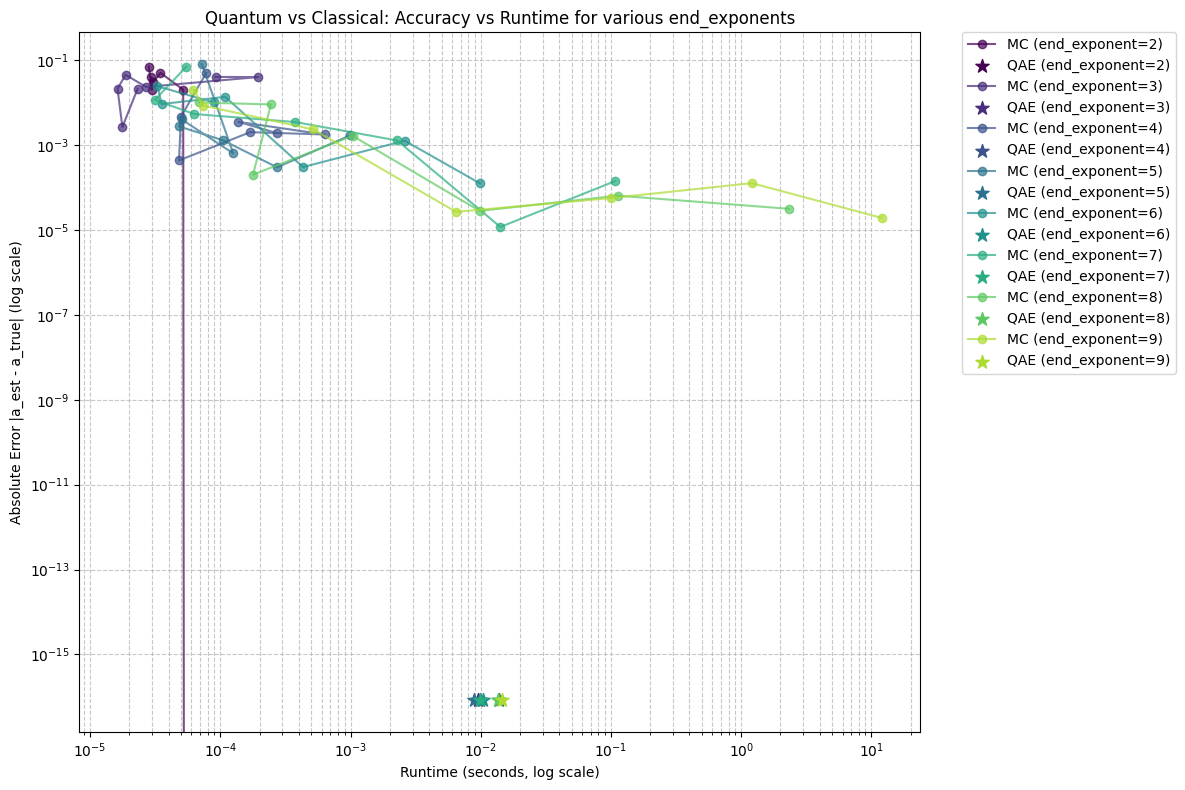

In [ ]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

# Define a colormap to get distinct colors for each end_exponent
cmap = plt.colormaps.get_cmap('viridis')

for i, end_exponent in enumerate(all_end_exponents):
    color = cmap(i / len(all_end_exponents)) # Get a unique color for this end_exponent

    # Plot Classical Monte Carlo results
    plt.loglog(all_mc_times[i], all_mc_errors[i], 'o-',
               color=color, label=f'MC (end_exponent={end_exponent})', alpha=0.7)

    # Plot Quantum Amplitude Estimation result
    plt.scatter(all_qae_times[i], all_qae_errors[i],
                color=color, s=100, marker='*', zorder=5,
                label=f'QAE (end_exponent={end_exponent})')

plt.xlabel("Runtime (seconds, log scale)")
plt.ylabel("Absolute Error |a_est - a_true| (log scale)")
plt.title("Quantum vs Classical: Accuracy vs Runtime for various end_exponents")
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.legend(loc='best', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
plt.tight_layout()
plt.show()